# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [4]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion_name"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722
F1 macro test: 0.9710

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



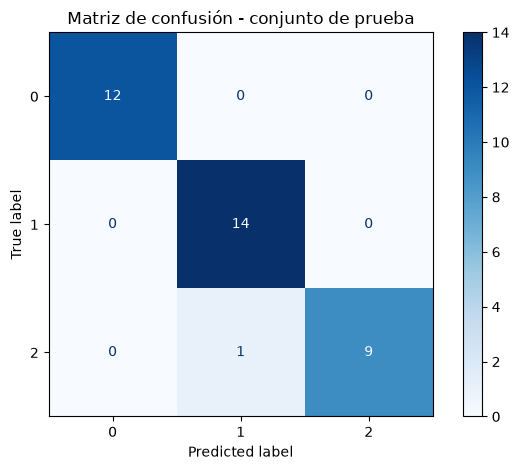

In [5]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy test: {accuracy:.4f}")
print(f"F1 macro test: {f1_macro:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión - conjunto de prueba")
plt.tight_layout()
plt.show()

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

## 3. Función de inferencia

In [6]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    missing_columns = [column for column in feature_columns if column not in records.columns]
    if missing_columns:
        raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

    ordered_records = records[feature_columns]
    predictions = model.predict(ordered_records)
    probabilities = model.predict_proba(ordered_records)

    result = pd.DataFrame(
        {
            "prediction": predictions,
        },
        index=records.index,
    )
    for class_index, class_name in enumerate(model.classes_):
        result[f"probability_{class_name}"] = probabilities[:, class_index]

    return result

## 4. Predicción por lotes

In [7]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
batch_predictions

,prediction,probability_0,probability_1,probability_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


## 5. Reporte final

In [8]:
test_metrics = {
    "model": training_metadata["champion_name"],
    "accuracy": accuracy,
    "f1_macro": f1_macro,
}

(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2),
    encoding="utf-8",
)

print(test_metrics)

{'model': 'logistic_regression', 'accuracy': 0.9722222222222222, 'f1_macro': 0.9709618874773139}


In [9]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | `logistic_regression` |
| Accuracy CV | 0.9791 |
| Accuracy test | 0.9722 |
| F1 macro test | 0.9710 |
| Clases más confundidas | Una muestra de la clase 2 fue predicha como clase 1 |
| Principal limitación | El conjunto de prueba es pequeño, con solo 36 registros |

El desempeño en test es coherente con la validación cruzada: la accuracy baja ligeramente de 0.9791 a 0.9722, sin evidencia fuerte de sobreajuste. La matriz de confusión muestra que las clases 0 y 1 se clasificaron correctamente, mientras que hubo una confusión entre las clases 2 y 1.

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.